# IND320 – Project work, part 3
**Name:** Kittel Johannes Lande

**Links**
**GitHub repository:** https://github.com/Kitteljl/IND320-app

**Streamlit app:** https://ind320-app-kittel.streamlit.app/

**Panopto Video:** https://nmbu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=815966aa-b126-4e25-98f6-b4f800c99047

**Contents**
1. Setup
2. Shapefiles and sampled locations
3. Open-Meteo download (ERA5)
4. Outliers: DCT + SPC (precipitation)
5. Anomalies: LOF (temperature)
6. STL decomposition (reservoir filling)
7. Spectrogram
8. AI usage
9. Log

# 1. Setup
Imports and configuration. Everything below runs top to bottom.

In [ ]:
# Run from the project root so that data/..., .streamlit/secrets.toml and our own
# modules (utils.py, weather.py, analysis.py, ...) are found when the notebook
# lives in the notebooks/ folder.
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

In [1]:
import os, time, glob
os.environ["TZ"] = "UTC"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import geopandas as gpd
import shapely

from utils import load_reservoir_data   # NVE Magasinstatistikk API (part 2)

%matplotlib inline
# (keep %matplotlib inline AFTER 'from utils import', since Streamlit sets the Agg backend)

SEED = 458
RNG = np.random.default_rng(SEED)       # same seed -> same sampled points every run

2026-11-03 12:05:54.188 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-03 12:05:54.189 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-03 12:05:54.190 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


# 2. Shapefiles and sampled locations
**Goal:** read the electricity-area and precipitation-area shapefiles from atlas.nve.no (East = RS + RØ, North = RM + RN), sample 1000 random locations per region and save them to `data/sample_points.csv` (columns: region, lon, lat) so the Streamlit app can read them without geopandas.

In [2]:
# Two shapefile sets from atlas.nve.no (both ETRS89 / UTM 33N, meters):
#   price_areas : Budomr_der.shp -> NO 1 ... NO 5 (column 'budomr')
#   nve_regions : NVE_Region.shp -> RV, RM, RN, RØ, RS (column 'REGION')
LAYERS = {"price_areas": ("Bud*.shp", "budomr"),
          "nve_regions": ("NVE_Region.shp", "REGION")}

parts = []
for layer, (fname, col) in LAYERS.items():
    gdf = gpd.read_file(glob.glob(f"data/**/{fname}", recursive=True)[0], encoding="utf-8")
    gdf["region"] = gdf[col].astype(str).str.replace(" ", "", regex=False)   # "NO 3" -> "NO3"
    gdf["layer"] = layer
    parts.append(gdf[["layer", "region", "geometry"]])
areas = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=parts[0].crs)
print(areas.crs)
areas[["layer", "region"]]

EPSG:25833


,layer,region
0,price_areas,NO1
1,price_areas,NO2
2,price_areas,NO3
3,price_areas,NO4
4,price_areas,NO5
5,nve_regions,RV
6,nve_regions,RM
7,nve_regions,RN
8,nve_regions,RØ
9,nve_regions,RS


In [3]:
N_POINTS = 1000

def sample_points(geom, n, rng):
    """Rejection sampling: uniform random points inside a (multi)polygon."""
    minx, miny, maxx, maxy = geom.bounds
    pts = []
    while len(pts) < n:
        x = rng.uniform(minx, maxx, 2 * n)
        y = rng.uniform(miny, maxy, 2 * n)
        keep = shapely.contains_xy(geom, x, y)      # True for points inside the polygon
        pts.extend(zip(x[keep], y[keep]))
    return pts[:n]

rows = []
for _, r in areas.iterrows():
    for x, y in sample_points(r.geometry, N_POINTS, RNG):
        rows.append((r["layer"], r["region"], x, y))

df = pd.DataFrame(rows, columns=["layer", "region", "x", "y"])
pts = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["x"], df["y"]),
                       crs=areas.crs).to_crs(4326)   # Open-Meteo wants lon/lat (WGS84)
pts["lon"], pts["lat"] = pts.geometry.x, pts.geometry.y
pts[["layer", "region", "lon", "lat"]].to_csv("data/sample_points.csv", index=False)

print(pts.groupby(["layer", "region"]).size())       # 1000 per region

layer        region
nve_regions  RM        1000
             RN        1000
             RS        1000
             RV        1000
             RØ        1000
price_areas  NO1       1000
             NO2       1000
             NO3       1000
             NO4       1000
             NO5       1000
dtype: int64


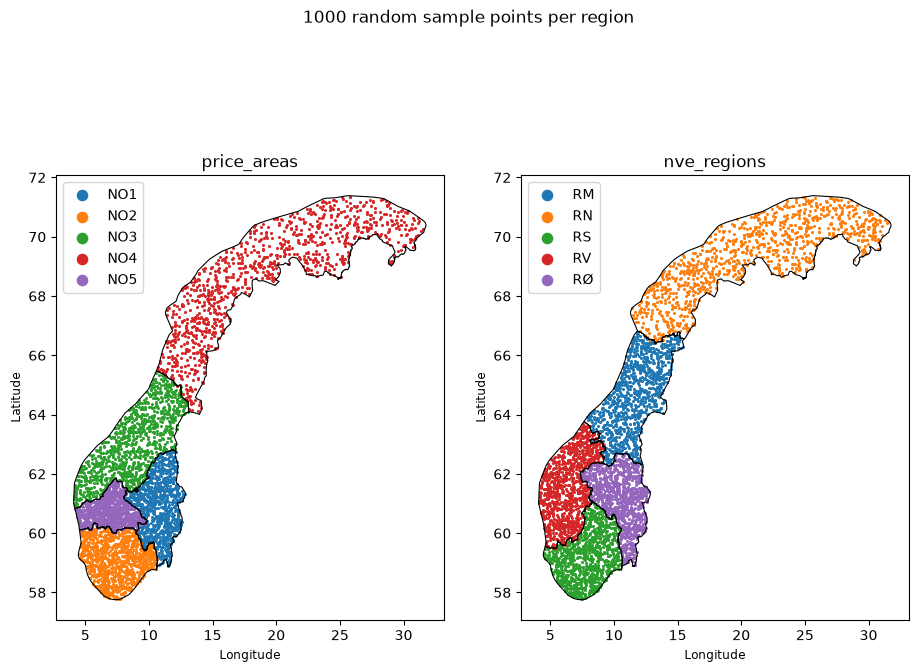

In [4]:
# Check: boundaries and sampled points for both layers (lon/lat)
fig, axes = plt.subplots(1, 2, figsize=(11, 8))
for ax, layer in zip(axes, LAYERS):
    areas[areas["layer"] == layer].to_crs(4326).boundary.plot(ax=ax, color="black", linewidth=0.8)
    for name, g in pts[pts["layer"] == layer].groupby("region"):
        ax.scatter(g["lon"], g["lat"], s=1.5, label=name)
    ax.legend(markerscale=6)
    ax.set_title(layer)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
plt.suptitle("1000 random sample points per region")
plt.show()

# 3. Open-Meteo download (ERA5)
**Goal:** function `download_weather(region, start, end)` that looks up the region's sampled coordinates, downloads hourly ERA5 data (at least precipitation and temperature, plus other relevant properties, e.g. wind speed, wind gusts, wind direction) and returns a data frame. Test: NO3, 2024.

Note: Open-Meteo has daily request limits, so data is downloaded for a subset of the sampled points (in batches) and averaged. Document the subset size in the log.

In [5]:
from weather import download_weather, get_points, region_id, HOURLY
print("Variables:", HOURLY)
get_points("NO3").head()

Variables: ['temperature_2m', 'precipitation', 'rain', 'snowfall', 'wind_speed_10m', 'wind_gusts_10m', 'wind_direction_10m']


,lon,lat
0,6.219134,61.719289
1,10.250063,62.566815
2,11.561720,63.798723
3,10.485097,64.562017
4,7.226064,62.727775


In [7]:
# NO3, 2024: 25 sampled locations, averaged hour by hour
weather_no3 = download_weather("NO3", "2024-01-01", "2024-12-31")
print(weather_no3.shape)                          # expect (8784, 7): 366 days x 24 hours
print(weather_no3.isna().sum().sum(), "missing values")
weather_no3.to_csv("data/weather_NO3_2024.csv")   # cache a copy so we avoid hitting the API again
weather_no3.head()

  downloaded 5/25 locations
  downloaded 10/25 locations
  downloaded 15/25 locations
  downloaded 20/25 locations
  downloaded 25/25 locations
(8784, 7)
0 missing values


,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,wind_gusts_10m,wind_direction_10m
time,,,,,,,
2024-01-01 00:00:00,-4.068,0.004,0.0,0.0028,21.620,52.648,123.835027
2024-01-01 01:00:00,-4.204,0.004,0.0,0.0028,22.104,52.860,124.340954
2024-01-01 02:00:00,-4.192,0.004,0.0,0.0028,22.380,53.068,124.981937
2024-01-01 03:00:00,-4.232,0.004,0.0,0.0028,22.384,53.200,125.075482
2024-01-01 04:00:00,-4.188,0.004,0.0,0.0028,22.412,53.320,125.107072


# 4. Outliers: DCT + SPC (precipitation)
**Goal:** plot average precipitation over time; high-pass filter with the Discrete Cosine Transform (SATV); draw SPC boundaries from robust statistics (median/MAD) of the whole year; colour outliers; do **not** plot the SATV itself.

Parameters with defaults: DCT frequency cut-off, number of standard deviations. Function returns the figure and a summary of the outliers.

In [8]:
from scipy.fft import dct, idct

def plot_spc_outliers(series, cutoff_freq=1/30, n_std=3.0, title="Precipitation"):
    """Outliers in hourly data via DCT high-pass filtering + Statistical Process Control.

    cutoff_freq : DCT cut-off in cycles per day (default 1/30 = periods longer than ~30 days
                  are treated as seasonal/slow variation and removed)
    n_std       : number of robust standard deviations for the SPC boundaries

    The high-pass filtered series (SATV) is only used to find the boundaries and outliers;
    it is not plotted. Returns the figure and a summary dict.
    """
    x = series.to_numpy(float)
    N = len(x)
    coef = dct(x, type=2, norm="ortho")
    k0 = int(np.ceil(cutoff_freq * 2 * N / 24))      # DCT index k <-> k*24/(2N) cycles/day (hourly data)
    low, high = coef.copy(), coef.copy()
    low[k0:] = 0                                     # keep slow variation
    high[:k0] = 0                                    # keep fast variation (SATV)
    slow = idct(low, type=2, norm="ortho")
    satv = idct(high, type=2, norm="ortho")

    # Robust statistics from the whole year: median and MAD (scaled to a standard deviation)
    center = np.median(satv)
    sigma = 1.4826 * np.median(np.abs(satv - center))
    is_out = np.abs(satv - center) > n_std * sigma

    # Boundaries drawn around the slow component, in the units of the original series
    upper = slow + center + n_std * sigma
    lower = slow + center - n_std * sigma

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, x, color="tab:blue", lw=0.6, label="Average precipitation")
    ax.plot(series.index, upper, color="black", lw=1, ls="--", label=f"SPC boundaries (±{n_std} robust SD)")
    ax.plot(series.index, lower, color="black", lw=1, ls="--")
    ax.scatter(series.index[is_out], x[is_out], color="tab:red", s=10, zorder=3, label="Outliers")
    ax.set_ylabel("Precipitation (mm/h)")
    ax.set_title(f"{title}: DCT cut-off {cutoff_freq:.3f} cycles/day, {n_std} SD")
    ax.legend(loc="upper right")
    fig.tight_layout()

    summary = {"n_outliers": int(is_out.sum()),
               "percent_outliers": round(float(100 * is_out.mean()), 2),
               "dct_coefficients_removed": k0,
               "robust_sigma": round(float(sigma), 4),
               "outliers": pd.DataFrame({"time": series.index[is_out], "precipitation": x[is_out]})}
    return fig, summary

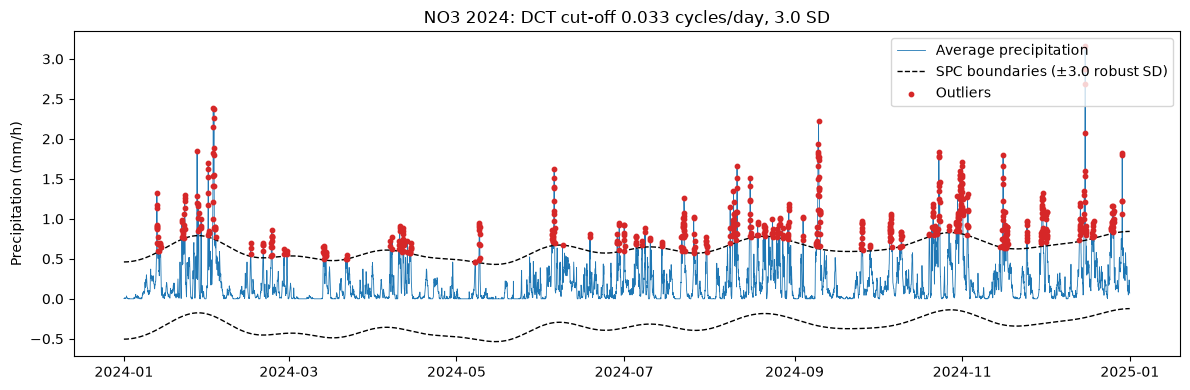

{'n_outliers': 629, 'percent_outliers': np.float64(7.16), 'dct_coefficients_removed': 25, 'robust_sigma': 0.1609}


,time,precipitation
0,2024-01-12 21:00:00,0.700
1,2024-01-12 22:00:00,0.884
2,2024-01-12 23:00:00,1.136
3,2024-01-13 00:00:00,1.328
4,2024-01-13 01:00:00,1.168


In [9]:
# Read the cached download so we don't need the API again
weather_no3 = pd.read_csv("data/weather_NO3_2024.csv", index_col="time", parse_dates=True)

fig, summary = plot_spc_outliers(weather_no3["precipitation"], title="NO3 2024")
plt.show()
print({k: v for k, v in summary.items() if k != "outliers"})
summary["outliers"].head()

# 5. Anomalies: LOF (temperature)
**Goal:** plot average temperature over time and mark anomalies found with Local Outlier Factor. Parameter: proportion of outliers (default 0.01). Function returns the figure and a summary.

In [10]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

def plot_lof_anomalies(series, contamination=0.01, n_neighbors=20, title="Temperature"):
    """Anomalies in hourly temperature with the Local Outlier Factor method.

    contamination : proportion of points flagged as anomalies (default 1 %)
    n_neighbors   : neighbourhood size used to estimate local density

    Features are the temperature and its hour-to-hour change (both standardised),
    so both unusual levels and unusually fast changes can be detected.
    Returns the figure and a summary dict.
    """
    x = series.to_numpy(float)
    feats = StandardScaler().fit_transform(np.column_stack([x, np.gradient(x)]))
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    is_out = lof.fit_predict(feats) == -1             # -1 = anomaly
    score = -lof.negative_outlier_factor_             # larger = more anomalous

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, x, color="tab:blue", lw=0.6, label="Average temperature")
    ax.scatter(series.index[is_out], x[is_out], color="tab:red", s=12, zorder=3, label="LOF anomalies")
    ax.set_ylabel("Temperature (°C)")
    ax.set_title(f"{title}: LOF, contamination={contamination:.1%}, n_neighbors={n_neighbors}")
    ax.legend(loc="upper right")
    fig.tight_layout()

    out = pd.DataFrame({"time": series.index[is_out], "temperature": x[is_out], "lof_score": score[is_out]})
    summary = {"n_anomalies": int(is_out.sum()),
               "percent_anomalies": round(float(100 * is_out.mean()), 2),
               "anomalies": out.sort_values("lof_score", ascending=False).reset_index(drop=True)}
    return fig, summary

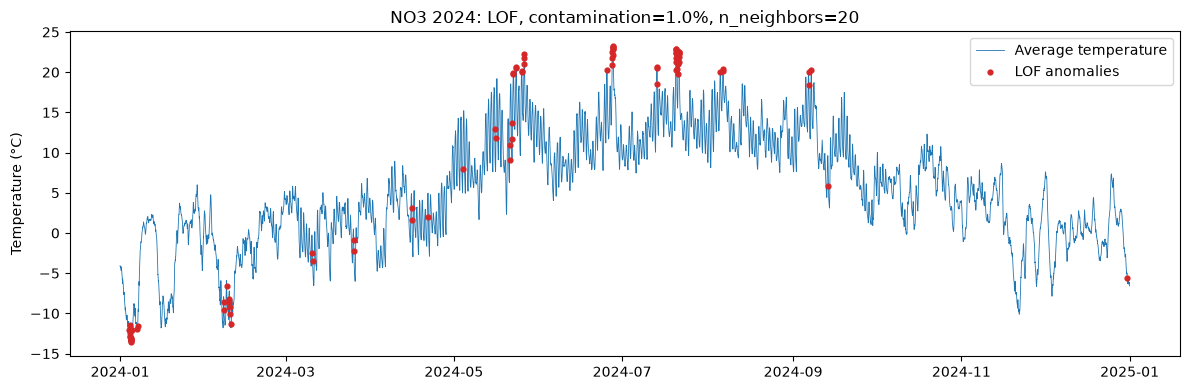

88 anomalies, 1.0 %


,time,temperature,lof_score
0,2024-02-09 16:00:00,-9.232,2.478961
1,2024-02-09 15:00:00,-8.196,2.423603
2,2024-02-07 16:00:00,-9.596,1.946309
3,2024-02-07 15:00:00,-8.532,1.801932
4,2024-07-20 19:00:00,20.420,1.708282


In [11]:
fig, summary = plot_lof_anomalies(weather_no3["temperature_2m"], title="NO3 2024")
plt.show()
print(summary["n_anomalies"], "anomalies,", summary["percent_anomalies"], "%")
summary["anomalies"].head()

# 6. STL decomposition (reservoir filling)
**Goal:** STL on the degree of filling from the Magasinstatistikk data; plot trend, seasonal and residual. Parameters with defaults: seasonal smoother, trend smoother, robust (True/False). Function returns the figure.

In [12]:
from statsmodels.tsa.seasonal import STL

def plot_stl(series, period=52, seasonal=13, trend=105, robust=True, title="STL decomposition"):
    """STL decomposition of a weekly series. Returns the figure.

    period   : observations per seasonal cycle (52 weeks = 1 year)
    seasonal : seasonal smoother length (odd; larger = smoother seasonal pattern)
    trend    : trend smoother length (odd, larger than period; larger = smoother trend)
    robust   : True downweights outliers in the fit
    """
    # Make the series regular (weekly) and fill small gaps so STL can run
    s = series.sort_index().resample("W").mean().interpolate()
    res = STL(s, period=period, seasonal=seasonal, trend=trend, robust=robust).fit()
    fig = res.plot()
    fig.set_size_inches(10, 8)
    fig.suptitle(f"{title} (seasonal={seasonal}, trend={trend}, robust={robust})", y=1.0)
    fig.tight_layout()
    return fig

2026-11-03 11:53:13.004 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-03 11:53:13.011 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


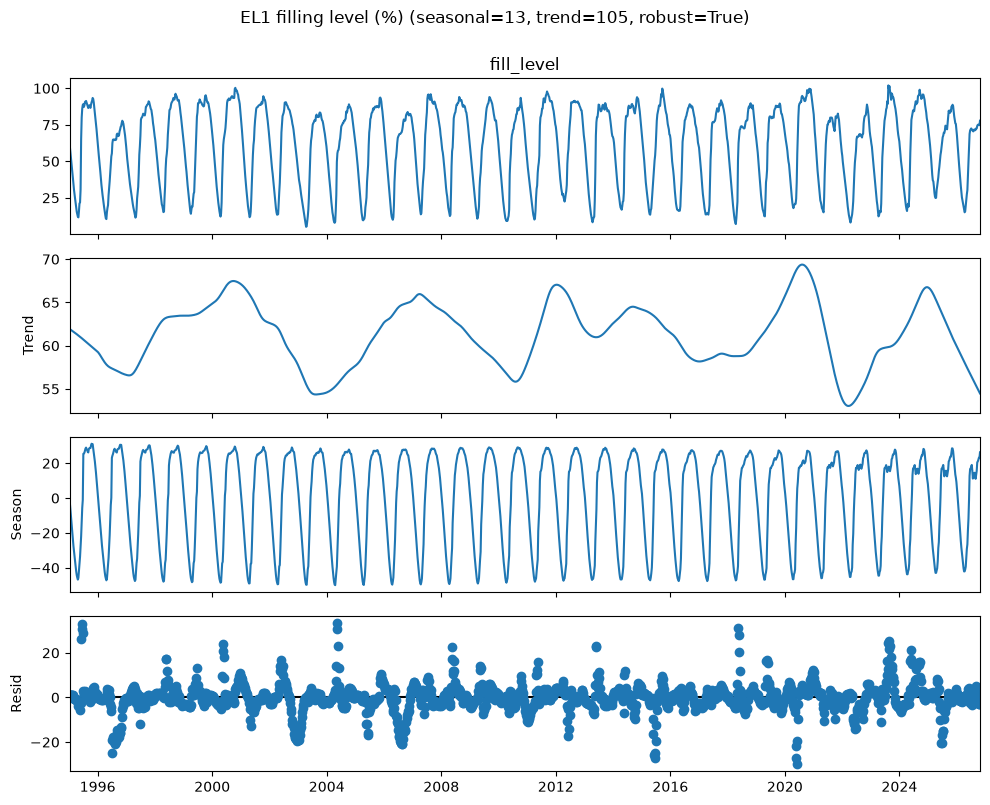

In [13]:
# Reservoir filling for one area (EL area 1) as a weekly time series
res_df = load_reservoir_data()
one = res_df[(res_df["area_type"] == "EL") & (res_df["area_number"] == 1)].set_index("date")
fig = plot_stl(one["fill_level"] * 100, title="EL1 filling level (%)")
plt.show()

# 7. Spectrogram
**Goal:** spectrogram of the same reservoir data. Parameters with defaults: window length, window overlap. Function returns the figure.

In [15]:
from scipy.signal import spectrogram

def plot_spectrogram(series, window_length=156, overlap=0.75, fmax=6, title="Spectrogram"):
    """Spectrogram of a weekly series. Returns the figure.

    window_length : window length in weeks (default 156 = 3 years)
    overlap       : fraction of the window shared by neighbouring windows (default 0.75)
    fmax          : highest frequency shown, in cycles per year
    """
    # Regular weekly series (fill small gaps), so 52 samples = 1 year
    s = series.sort_index().resample("W").mean().interpolate()
    x = s.to_numpy(float)

    nperseg = int(window_length)
    noverlap = int(overlap * nperseg)
    # fs = 52 samples/year -> frequencies come out in cycles per year
    f, t, Sxx = spectrogram(x, fs=52, window="hann", nperseg=nperseg,
                            noverlap=noverlap, detrend="constant", scaling="density")

    # Segment centres (in years) -> dates
    dates = s.index[0] + pd.to_timedelta(t * 365.25, unit="D")

    fig, ax = plt.subplots(figsize=(11, 4.5))
    mesh = ax.pcolormesh(dates, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="viridis")
    ax.set_ylim(0, fmax)
    ax.set_ylabel("Frequency (cycles per year)")
    ax.set_title(f"{title}: window={window_length} weeks, overlap={overlap:.0%}")
    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    fig.tight_layout()
    return fig

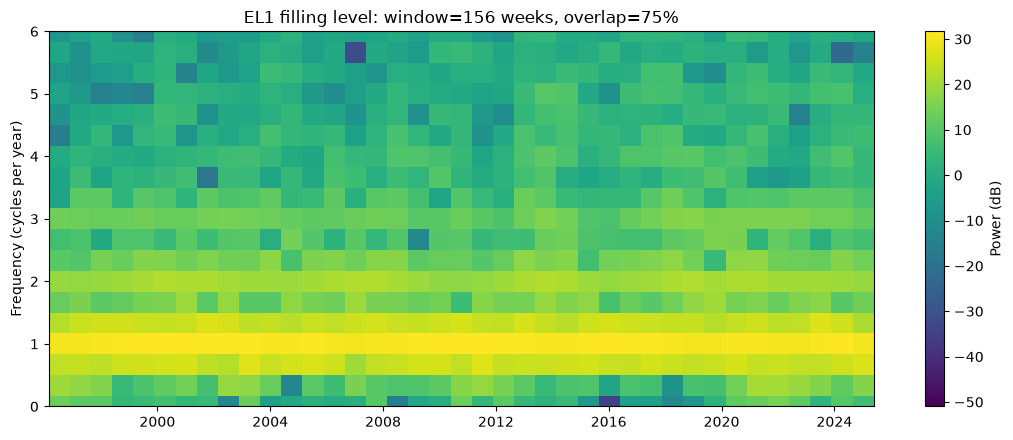

In [16]:
fig = plot_spectrogram(one["fill_level"] * 100, title="EL1 filling level")
plt.show()

In [2]:
from utils import reservoir_series
s = reservoir_series("EL", 1, 2015, 2025)
print(s.shape, s.index.min(), s.index.max())

2026-11-03 12:06:00.947 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-03 12:06:00.950 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-03 12:06:00.951 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


(574,) 2015-01-04 00:00:00 2025-12-28 00:00:00


# 8. AI usage
I used Claude (Anthropic) as a coding assistant throughout this part, working step by step.

**What it helped with**
- Structuring the workflow: shapefiles, random sampling of 1000 locations per region, the Open-Meteo (ERA5) download function, and the four analysis functions (DCT + SPC, LOF, STL, spectrogram) with their parameters and defaults.
- Debugging: shapefile file names and text encoding (Norwegian characters), a missing `RNG` definition, and Open-Meteo timeouts and HTTP 503 errors (smaller batches, retries, a subset of locations to respect API limits).
- Explaining methods, for example how DCT coefficients map to frequencies and why a robust median/MAD estimate is used for the SPC boundaries.

**What I did and checked myself**
- Downloaded the shapefiles from atlas.nve.no and decided how the NVE regions map to the VASS areas (VASS1 = RS + RØ, VASS2 = RV, VASS3 = RM + RN).
- Ran all code and checked the results: 1000 points per region on a map, 8784 hourly rows for NO3 in 2024 (366 days × 24 hours), no missing values, and that the outlier and anomaly counts and the plots look reasonable (for example 88 anomalies = 1 % for LOF).
- Chose parameters and wrote the interpretation of the results and this log myself.

# 9. Log

**Notebook.** This part added weather data and four analysis methods to the project. I started with the two shapefile sets from atlas.nve.no: the electricity price areas (NO1–NO5) and the NVE regions (RV, RM, RN, RØ, RS). Both were in UTM 33N, so I sampled 1000 random points per region with a seeded random generator and converted them to longitude/latitude. The VASS areas used by Magasinstatistikk are built from the NVE regions (VASS1 = RS + RØ, VASS2 = RV, VASS3 = RM + RN). The points are saved in a small CSV file so the Streamlit app can use them without geopandas. One practical problem was the Norwegian characters in the shapefile, which came out garbled until I read the file as UTF-8.

The download function takes a region identifier and a time interval, looks up the sampled coordinates and fetches hourly ERA5 data from Open-Meteo: temperature, precipitation, rain, snowfall, wind speed, wind gusts and wind direction. Downloading all 1000 points would break the API limits, so the function uses a subset of 25 points per region, in small batches, and averages them hour by hour (wind direction as a circular mean). The API first timed out and then returned HTTP 503, so I added retries and waiting. NO3 for 2024 gives 8784 hourly rows (366 days × 24 hours) without missing values.

Precipitation outliers are found by high-pass filtering with the Discrete Cosine Transform, then estimating a median and MAD from the whole year and drawing limits of ± n robust standard deviations around the slow variation. With the defaults (30-day cut-off, 3 SD) about 7 % of the hours are outliers, which is expected because most hours are nearly dry. Temperature anomalies use Local Outlier Factor on temperature and its hourly change, with 1 % flagged as default. STL and the spectrogram use the weekly filling level; the spectrogram shows a clear annual band.

**Streamlit.** I moved the analysis functions into `analysis.py` and the weather download into `weather.py`, so both the notebook and the app use the same code. The weather download is cached for 24 hours per area and year. The area type (EL/NO/VASS) and download interval come from the shared sidebar controls; area number and year are local choices on the weather pages, and NO (the whole country) has no weather region, so the page explains this. I made one new page with tabs for STL and the spectrogram, and one with tabs for the SPC outliers and the LOF anomalies. The pages are grouped as reservoirs, weather and cross-border flows.

I developed on a separate branch (`part3`) and will merge into main after the peer review. The assignment text mentions temperature for the DCT/SPC step but precipitation elsewhere; I followed the precipitation wording.